# Chalet

Forecast for now, estimated new snow and sunshine for the next 48 h, a daily outlook, and the SLF avalanche bulletin (danger level, main problem, aspects, altitude).

Snowfall is not a published parameter: it is estimated from forecast precipitation and the zero-degree level (rain→snow ramp 500–100 m below it), at ~1 cm of snow per mm of water.

Data: MeteoSwiss local forecast (OGD); avalanche bulletin © SLF.

In [1]:
import json
import localforecast as lf
import screens

In [2]:
# Find point ids: search by town, station abbreviation or postal code
lf.find_point("Chandolin")

,point_id,point_type_id,point_name,station_abbr,postal_code,point_type_en,point_height_masl
2870,396123,2,Chandolin,NaN,3961.0,Postal code center,1900.0


In [3]:
# SLF warning regions — pick the one containing the chalet
{k: v for k, v in lf.slf_regions().items() if "Anniviers" in v or "Montana" in v}

{'CH-4121': 'Montana', 'CH-4124': "Val d'Anniviers"}

In [4]:
# ── Configuration ──────────────────────────────────────────────
POINT = (396123, 2)       # Chandolin, postal code 3961, 1900 m
SLF_REGION = "CH-4124"    # Val d'Anniviers
SLF_STATION = "ANV2"      # Orzival, 2640 m: measured snow depth (SLF IMIS)
# Outside the season there is no bulletin; set a winter time to try the layout
SLF_ACTIVE_AT = None      # e.g. "2026-02-15T10:00:00Z"
HOURS, DAYS = 39, 5       # chart: 39 h from the last 00:00 / 12:00, daily outlook days
# ───────────────────────────────────────────────────────────────

No avalanche bulletin for this region now


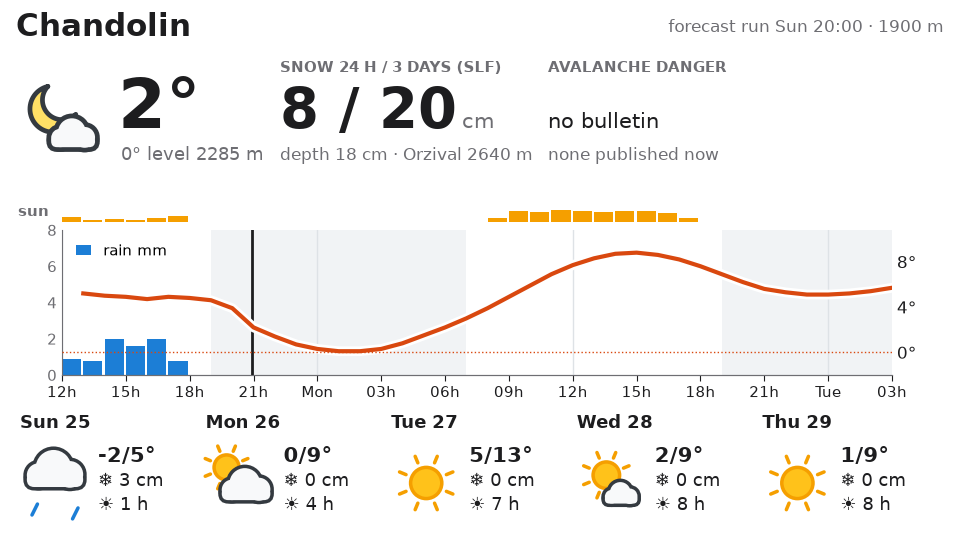

In [5]:
run, data = lf.fetch([POINT], lf.CHALET_PARAMS)
hourly, daily = data[POINT]
bulletin = lf.slf_bulletin(SLF_REGION, active_at=SLF_ACTIVE_AT)
if bulletin is None:
    print("No avalanche bulletin for this region now")
station = lf.slf_station(SLF_STATION)
view = lf.chalet_view(run, hourly, daily, lf.point_info(POINT), bulletin, station, hours=HOURS, days=DAYS)
screens.render(screens.chalet, view, colour=True)

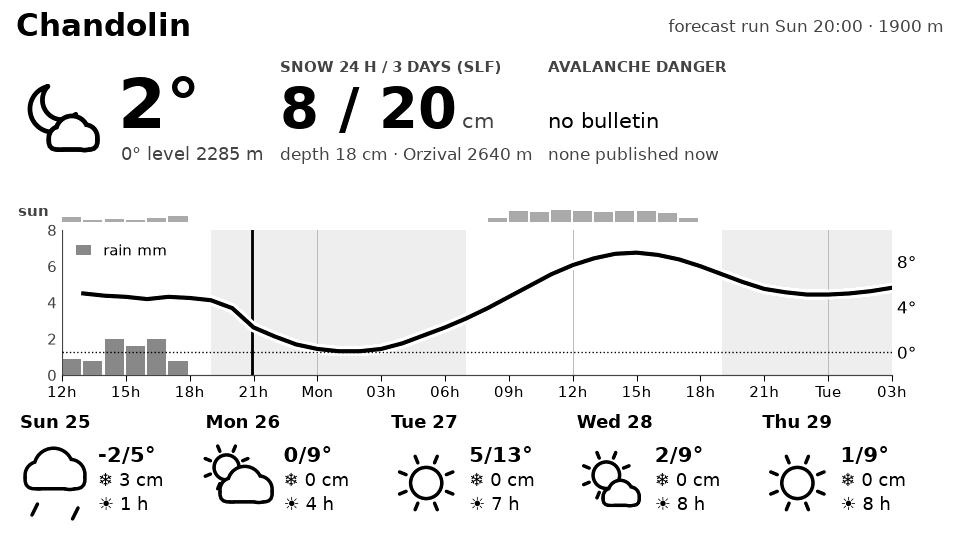

In [6]:
# As on the LilyGO T5 4.7" e-paper: 960×540, 16 grey levels
img = screens.render(screens.chalet, view)
img

In [7]:
# The payload a display would receive
print(f"{len(json.dumps(view, separators=(',', ':')))} bytes as JSON, "
      f"{len(screens.epd_buffer(img)):,} bytes as a 4-bit frame buffer")
print(json.dumps(view, indent=1)[:1500])

2940 bytes as JSON, 259,200 bytes as a 4-bit frame buffer
{
 "view": "chalet",
 "name": "Chandolin",
 "alt": 1900.0,
 "run": "2026-10-25T20:00:00+01:00",
 "now": {
  "time": "2026-10-25T21:00:00+01:00",
  "temp": 2.2,
  "icon": 102,
  "freezing_m": 2285
 },
 "hourly": {
  "time": [
   "2026-10-25T13:00:00+01:00",
   "2026-10-25T14:00:00+01:00",
   "2026-10-25T15:00:00+01:00",
   "2026-10-25T16:00:00+01:00",
   "2026-10-25T17:00:00+01:00",
   "2026-10-25T18:00:00+01:00",
   "2026-10-25T19:00:00+01:00",
   "2026-10-25T20:00:00+01:00",
   "2026-10-25T21:00:00+01:00",
   "2026-10-25T22:00:00+01:00",
   "2026-10-25T23:00:00+01:00",
   "2026-10-26T00:00:00+01:00",
   "2026-10-26T01:00:00+01:00",
   "2026-10-26T02:00:00+01:00",
   "2026-10-26T03:00:00+01:00",
   "2026-10-26T04:00:00+01:00",
   "2026-10-26T05:00:00+01:00",
   "2026-10-26T06:00:00+01:00",
   "2026-10-26T07:00:00+01:00",
   "2026-10-26T08:00:00+01:00",
   "2026-10-26T09:00:00+01:00",
   "2026-10-26T10:00:00+01:00",
   "2026-10-2